<a href="https://colab.research.google.com/github/Sanjarbek9706/Sanjarbek9706/blob/main/face_expression_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install mediapipe


In [2]:
from pathlib import Path
import base64
import urllib.request

import cv2
import mediapipe as mp
import numpy as np
from IPython.display import Javascript, display
from google.colab import files
from google.colab.output import eval_js

MODEL_PATH = Path('/content/face_landmarker.task')
MODEL_URL = 'https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task'
if not MODEL_PATH.exists():
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode
options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=True,
)
landmarker = FaceLandmarker.create_from_options(options)
print('Model tayyor')


Model tayyor


In [3]:
# Tajriba uchun boshlang‘ich chegaralar. Yorug‘lik va yuzga qarab sozlash mumkin.
SMILE_THRESHOLD = 0.45
SLEEPY_BLINK_THRESHOLD = 0.60
YAWN_THRESHOLD = 0.60
FROWN_THRESHOLD = 0.30
BROW_UP_THRESHOLD = 0.25

def average(scores, left, right):
    return (scores.get(left, 0.0) + scores.get(right, 0.0)) / 2

def analyze_face(rgb):
    image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))
    result = landmarker.detect(image)
    if not result.face_landmarks:
        return 'NO FACE', {}, None

    scores = {c.category_name: c.score for c in result.face_blendshapes[0]}
    smile = average(scores, 'mouthSmileLeft', 'mouthSmileRight')
    blink = average(scores, 'eyeBlinkLeft', 'eyeBlinkRight')
    frown = average(scores, 'mouthFrownLeft', 'mouthFrownRight')
    brow_up = scores.get('browInnerUp', 0.0)
    jaw_open = scores.get('jawOpen', 0.0)

    # Ustuvorlik: tabassum, yopiq ko‘z/esnash, keyin xafa yuz ifodasi.
    if smile >= SMILE_THRESHOLD:
        label = 'SMILING'
    elif blink >= SLEEPY_BLINK_THRESHOLD or (jaw_open >= YAWN_THRESHOLD and smile < 0.25):
        label = 'SLEEPY (demo)'
    elif frown >= FROWN_THRESHOLD and brow_up >= BROW_UP_THRESHOLD:
        label = 'CRYING (demo)'
    else:
        label = 'NEUTRAL'

    metrics = {'smile': smile, 'blink': blink, 'jaw_open': jaw_open,
               'frown': frown, 'brow_inner_up': brow_up}
    return label, metrics, result.face_landmarks[0]

def show_result(rgb):
    label, metrics, landmarks = analyze_face(rgb)
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    h, w = bgr.shape[:2]
    if landmarks:
        xs = [p.x * w for p in landmarks]
        ys = [p.y * h for p in landmarks]
        x1, y1 = max(0, int(min(xs))), max(0, int(min(ys)))
        x2, y2 = min(w-1, int(max(xs))), min(h-1, int(max(ys)))
        cv2.rectangle(bgr, (x1, y1), (x2, y2), (255, 255, 0), 2)
    color = (0, 220, 0) if label == 'SMILING' else (0, 220, 255)
    cv2.rectangle(bgr, (0, 0), (w, 52), (15, 20, 30), -1)
    cv2.putText(bgr, label, (12, 37), cv2.FONT_HERSHEY_SIMPLEX,
                0.95, color, 2, cv2.LINE_AA)
    display(mp_image_from_bgr(bgr))
    print(label, {k: round(v, 3) for k, v in metrics.items()})
    return label

def mp_image_from_bgr(bgr):
    # Notebookda rasmni ko‘rsatish uchun JPEG baytlari.
    from IPython.display import Image
    ok, encoded = cv2.imencode('.jpg', bgr)
    if not ok:
        raise RuntimeError('Natijani JPEG formatiga o‘tkazib bo‘lmadi')
    return Image(data=encoded.tobytes())


<IPython.core.display.Javascript object>

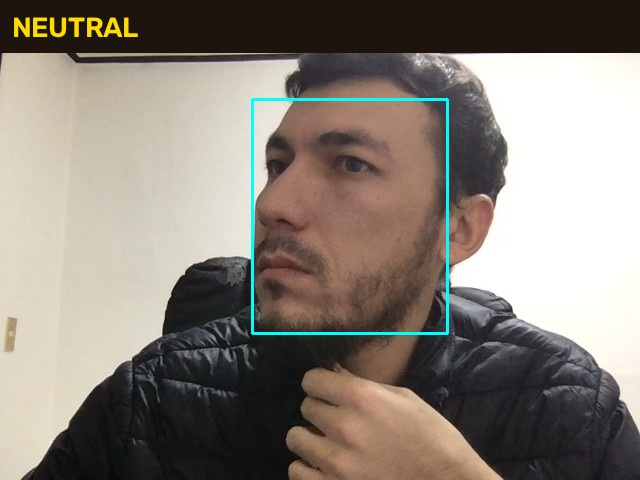

NEUTRAL {'smile': 0.008, 'blink': 0.115, 'jaw_open': 0.001, 'frown': 0.011, 'brow_inner_up': 0.018}


In [6]:
# Kameradan bitta surat olib holatini aniqlash.
js = '''async function takePhoto() {
  const video = document.createElement('video');
  let stream;
  try {
    stream = await navigator.mediaDevices.getUserMedia({video: true, audio: false});
    video.srcObject = stream;
    video.style.maxWidth = '420px';
    document.body.appendChild(video);
    await video.play();
    await new Promise(resolve => setTimeout(resolve, 3000));
    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);
    return canvas.toDataURL('image/jpeg', 0.9);
  } finally {
    if (stream) stream.getTracks().forEach(track => track.stop());
    video.remove();
  }
}'''
display(Javascript(js))
try:
    data_url = eval_js('takePhoto()')
    raw = base64.b64decode(data_url.split(',', 1)[1])
except Exception as exc:
    print('Kamera ochilmadi:', exc)
    print('Colab sahifasiga Camera: Allow ruxsatini bering yoki rasm yuklab sinang.')
    uploaded = files.upload()
    raw = next(iter(uploaded.values())) if uploaded else None
if raw is not None:
    bgr = cv2.imdecode(np.frombuffer(raw, dtype=np.uint8), cv2.IMREAD_COLOR)
    if bgr is None:
        raise RuntimeError('Surat ochilmadi')
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    show_result(rgb)
else:
    print('Ruxsatni o‘zgartirgach shu katakni qayta ishga tushiring.')
